# 3. ES 15min Mean Reversion - Robustness Testing
## Professional Validation Framework with Realistic Costs

This notebook performs advanced robustness tests on the ES 15min Mean Reversion strategy using the **optimal parameters from 02_MR_Optimization** and realistic costs.

**Optimal Parameters (from 02):**
- Entry Threshold: 1.0%
- RSI(2) Threshold: 13
- ATR Stop Multiplier: 1.3x
- ATR Target Multiplier: 3.0x
- Time Stop: 3:50 PM NY

**Cost Assumptions (1 contract ES):**
- Commission: $2.00 per side = $4.00 round trip
- Slippage: 0.5 ticks = $6.25
- Total cost per trade: **$10.25**

**Tests:**
1. Out-of-Sample Backtest
2. Walk-Forward Analysis
3. Parameter Sensitivity (Plateau)
4. Stress Tests (Extreme Events)
5. Monte Carlo with Variable Slippage
6. Final Decision Criteria

In [10]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. CONFIGURE PATHS AND IMPORT

In [11]:
project_root = Path().resolve().parent.parent
sys.path.append(str(project_root / 'utils'))

from utils import (
    load_data_from_mongo,
    prepare_data,
    run_backtest,
    compute_metrics,
    walk_forward_analysis,
    monte_carlo_bootstrap,
    parameter_sensitivity_analysis,
    plot_equity_curve,
    plot_trade_distribution
)

# Plot styling
sns.set_style("whitegrid")
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

print("✅ Utils imported successfully.")

✅ Utils imported successfully.


# 2. LOAD DATA, COSTS, AND FINAL PARAMETERS

In [12]:
# Load data
df_15min = load_data_from_mongo('es_15min')

print(f"✅ Data loaded: {len(df_15min)} bars")
print(f"   Date range: {df_15min.index.min()} → {df_15min.index.max()}")

# Split data (for reference)
df_is = df_15min[(df_15min.index >= '2009-09-27') & (df_15min.index < '2020-01-01')].copy()
df_oos = df_15min[df_15min.index >= '2020-01-01'].copy()

print(f"\n📊 In-Sample (IS): {len(df_is)} bars ({df_is.index.min()} → {df_is.index.max()})")
print(f"📊 Out-of-Sample (OOS): {len(df_oos)} bars ({df_oos.index.min()} → {df_oos.index.max()})")

# --- Define realistic costs for ES (1 contract) ---
COMMISSION_PER_CONTRACT = 2.0  # $2 per side = $4 round trip
SLIPPAGE_TICKS = 0.5           # 0.5 ticks = $6.25
SLIPPAGE_COST = SLIPPAGE_TICKS * 12.50
COST_PER_TRADE = COMMISSION_PER_CONTRACT * 2 + SLIPPAGE_COST

print("\n" + "="*70)
print("COST ASSUMPTIONS (1 contract ES)")
print("="*70)
print(f"Commission (round trip): ${COMMISSION_PER_CONTRACT * 2:.2f}")
print(f"Slippage: {SLIPPAGE_TICKS} tick(s) = ${SLIPPAGE_COST:.2f}")
print(f"Total cost per trade: ${COST_PER_TRADE:.2f}")

# --- FINAL OPTIMAL PARAMETERS (from 02_MR_Optimization) ---
# IMPORTANT: Update these values with what 02 gave you!
OPTIMAL_PARAMS = {
    'entry_threshold': 1.0,
    'rsi_threshold': 14,
    'atr_stop': 1.4,
    'atr_target': 3.0
}

print("\n" + "="*70)
print("FINAL PARAMETERS (from 02)")
print("="*70)
for k, v in OPTIMAL_PARAMS.items():
    print(f"  {k}: {v}")

✅ Data loaded: 397663 bars
   Date range: 2009-09-27 18:00:00 → 2026-08-21 16:45:00

📊 In-Sample (IS): 241077 bars (2009-09-27 18:00:00 → 2019-12-31 16:45:00)
📊 Out-of-Sample (OOS): 156586 bars (2020-01-01 18:00:00 → 2026-08-21 16:45:00)

COST ASSUMPTIONS (1 contract ES)
Commission (round trip): $4.00
Slippage: 0.5 tick(s) = $6.25
Total cost per trade: $10.25

FINAL PARAMETERS (from 02)
  entry_threshold: 1.0
  rsi_threshold: 14
  atr_stop: 1.4
  atr_target: 3.0


# 3. OOS BACKTEST WITH FINAL PARAMETERS (WITH REALISTIC COSTS)


OOS BACKTEST WITH FINAL PARAMETERS
Number of trades: 41
Win rate: 39.02%
Average win: 1.60%
Average loss: -1.06%
Profit Factor: 0.97
Expectancy per trade: -0.0197%
Total P&L: -0.81%
Sharpe Ratio: -0.21
Maximum Drawdown: -7.04%


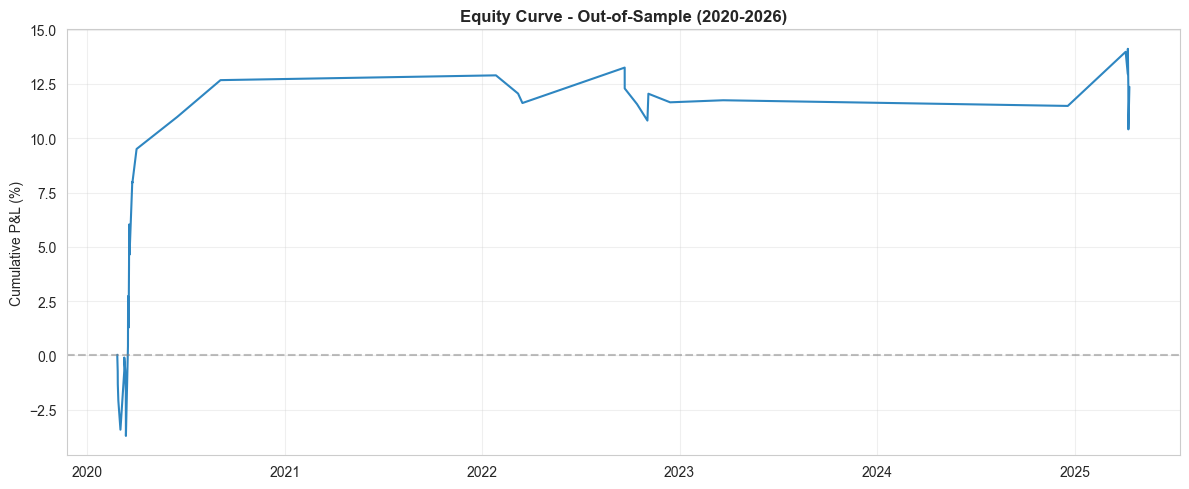

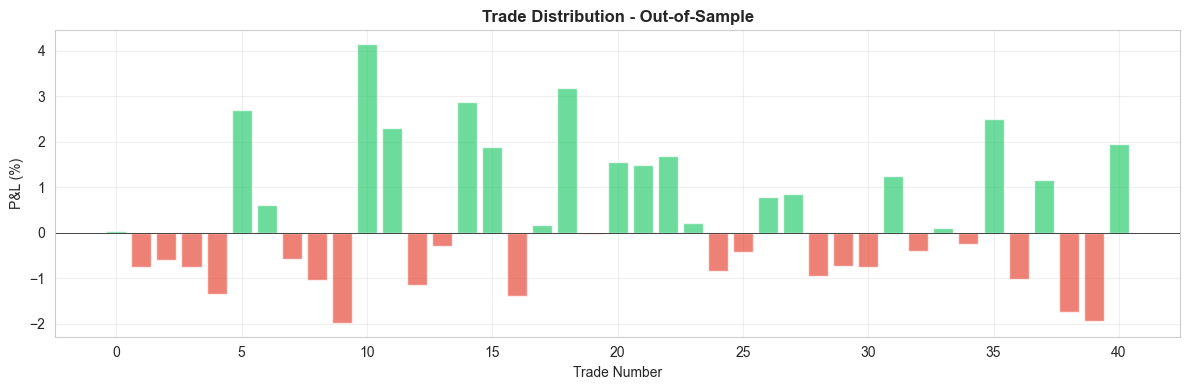

In [13]:
print("\n" + "="*70)
print("OOS BACKTEST WITH FINAL PARAMETERS")
print("="*70)

df_oos_prep = prepare_data(
    df_oos,
    OPTIMAL_PARAMS['entry_threshold'],
    OPTIMAL_PARAMS['rsi_threshold'],
    OPTIMAL_PARAMS['atr_stop'],
    OPTIMAL_PARAMS['atr_target']
)

trades_oos = run_backtest(
    df_oos_prep,
    OPTIMAL_PARAMS['atr_stop'],
    OPTIMAL_PARAMS['atr_target']
)

metrics_oos = compute_metrics(trades_oos, cost_per_trade=COST_PER_TRADE)

print(f"Number of trades: {metrics_oos['num_trades']}")
print(f"Win rate: {metrics_oos['win_rate']:.2f}%")
print(f"Average win: {metrics_oos['avg_win']:.2f}%")
print(f"Average loss: {metrics_oos['avg_loss']:.2f}%")
print(f"Profit Factor: {metrics_oos['profit_factor']:.2f}")
print(f"Expectancy per trade: {metrics_oos['expectancy']:.4f}%")
print(f"Total P&L: {metrics_oos['total_pnl']:.2f}%")
print(f"Sharpe Ratio: {metrics_oos['sharpe']:.2f}")
print(f"Maximum Drawdown: {metrics_oos['max_drawdown']:.2f}%")

# Equity curve
if len(trades_oos) > 0:
    plot_equity_curve(trades_oos, title='Equity Curve - Out-of-Sample (2020-2026)')
    plot_trade_distribution(trades_oos, title='Trade Distribution - Out-of-Sample')

# 4. WALK-FORWARD ANALYSIS

In [14]:
print("\n" + "="*70)
print("WALK-FORWARD ANALYSIS")
print("="*70)

wfo_results = walk_forward_analysis(
    df_15min,
    param_grid=None,
    train_years=5,
    test_years=1,
    start_year=2010,
    end_year=2021,
    cost_per_trade=COST_PER_TRADE
)

if len(wfo_results) > 0:
    print(wfo_results[['test_start', 'test_end', 'pf', 'win_rate', 'num_trades', 'max_dd']].to_string(index=False))
    
    avg_pf = wfo_results['pf'].mean()
    std_pf = wfo_results['pf'].std()
    print(f"\nAverage PF (OOS): {avg_pf:.2f} (+/- {std_pf:.2f})")
    print(f"Minimum PF: {wfo_results['pf'].min():.2f}")
    print(f"Maximum PF: {wfo_results['pf'].max():.2f}")
    
    if avg_pf > 1.3 and std_pf < 0.3 and wfo_results['pf'].min() > 1.1:
        print("✅ PASS: Walk-Forward shows consistent edge across multiple market regimes.")
    else:
        print("⚠️ WARNING: Walk-Forward performance is inconsistent or weak. Proceed with caution.")
else:
    print("⚠️ WARNING: No WFO cycles completed. Data may be insufficient.")


WALK-FORWARD ANALYSIS

SEQUENTIAL OPTIMIZATION

Step 1: Optimizing Entry Threshold
 threshold  num_trades  win_rate  profit_factor  expectancy     sharpe  max_drawdown
       0.5         151  9.271523       0.041729   -0.969739 -20.494931   -145.295919
       0.7          57 12.280702       0.079392   -1.011248 -17.268155    -56.711661
       1.0          15 13.333333       0.186134   -0.910600 -11.821501    -12.119071

Best threshold: 1.0

Step 2: Optimizing RSI Threshold
 rsi  num_trades  win_rate  profit_factor  expectancy     sharpe  max_drawdown
  15          14 21.428571       0.270080   -0.761771  -9.005124     -9.124858
  20          15 13.333333       0.186134   -0.910600 -11.821501    -12.119071
  25          15 13.333333       0.186134   -0.910600 -11.821501    -12.119071

Best RSI: 15

Step 3: Optimizing ATR Stop Multiplier
 stop  num_trades  win_rate  profit_factor  expectancy    sharpe  max_drawdown
  1.5          14 21.428571       0.271381   -0.756768 -9.579272     -9.

# 5. PARAMETER SENSITIVITY ANALYSIS (PLATEAU)

In [15]:
print("\n" + "="*70)
print("PARAMETER SENSITIVITY ANALYSIS")
print("="*70)

variations = {
    'entry_threshold': [0.8, 1.2],
    'rsi_threshold': [12, 18],
    'atr_stop': [1.2, 1.8],
    'atr_target': [2.4, 3.6]
}

sensitivity_results = parameter_sensitivity_analysis(
    df_oos, 
    OPTIMAL_PARAMS, 
    variations,
    cost_per_trade=COST_PER_TRADE
)

if len(sensitivity_results) > 0:
    print(sensitivity_results.to_string(index=False))
    
    pf_range = sensitivity_results['profit_factor'].max() - sensitivity_results['profit_factor'].min()
    print(f"\n📊 Profit Factor range: {pf_range:.2f}")
    
    if pf_range < 0.5:
        print("✅ Robust: PF is stable across parameter variations (range < 0.5).")
    else:
        print("⚠️ Warning: PF varies significantly. System may be fragile.")
else:
    print("⚠️ WARNING: No sensitivity results.")


PARAMETER SENSITIVITY ANALYSIS
          param  value  num_trades  profit_factor  expectancy  total_pnl  max_drawdown
entry_threshold    0.8          80       0.616573   -0.250284 -20.022726    -23.757991
entry_threshold    1.2          22       0.846875   -0.117694  -2.589277     -4.784973
  rsi_threshold   12.0          39       1.069470    0.040996   1.598849     -7.241968
  rsi_threshold   18.0          44       1.046841    0.029216   1.285511     -7.367081
       atr_stop    1.2          42       1.063327    0.036267   1.523207     -6.337710
       atr_stop    1.8          41       0.993934   -0.004138  -0.169661     -8.671465
     atr_target    2.4          42       0.899368   -0.064134  -2.693638     -7.582336
     atr_target    3.6          40       0.866460   -0.094406  -3.776241     -6.500361

📊 Profit Factor range: 0.45
✅ Robust: PF is stable across parameter variations (range < 0.5).


# 6. STRESS TESTS (EXTREME EVENTS)

In [16]:
print("\n" + "="*70)
print("STRESS TESTS (EXTREME EVENTS)")
print("="*70)

events = {
    'COVID Crash': ('2020-03-01', '2020-04-30'),
    'Bear Market 2022': ('2022-01-01', '2022-12-31'),
    'Rally 2023-2024': ('2023-01-01', '2024-12-31'),
    'Full OOS (2020-2026)': ('2020-01-01', '2026-08-21')
}

stress_results = []

for event_name, (start, end) in events.items():
    df_event = df_15min[(df_15min.index >= start) & (df_15min.index <= end)].copy()
    if len(df_event) == 0:
        continue
    
    df_prep = prepare_data(
        df_event,
        OPTIMAL_PARAMS['entry_threshold'],
        OPTIMAL_PARAMS['rsi_threshold'],
        OPTIMAL_PARAMS['atr_stop'],
        OPTIMAL_PARAMS['atr_target']
    )
    trades = run_backtest(df_prep, OPTIMAL_PARAMS['atr_stop'], OPTIMAL_PARAMS['atr_target'])
    metrics = compute_metrics(trades, cost_per_trade=COST_PER_TRADE)
    
    stress_results.append({
        'event': event_name,
        'num_trades': metrics['num_trades'],
        'pf': metrics['profit_factor'],
        'total_pnl': metrics['total_pnl'],
        'max_dd': metrics['max_drawdown'],
        'sharpe': metrics['sharpe']
    })

stress_df = pd.DataFrame(stress_results)
print(stress_df.to_string(index=False))

if len(stress_df) > 0:
    if all(stress_df['pf'] > 1.1):
        print("\n✅ PASS: Strategy survived all extreme events with PF > 1.1.")
    else:
        print("\n❌ FAIL: Strategy underperformed during one or more extreme events.")
else:
    print("⚠️ WARNING: No stress test results.")


STRESS TESTS (EXTREME EVENTS)
               event  num_trades       pf  total_pnl    max_dd     sharpe
         COVID Crash          17 1.406560   4.615843 -4.820631   2.289965
    Bear Market 2022          10 0.362474  -3.619908 -3.915695  -7.142077
     Rally 2023-2024           2 0.000000  -0.596888 -0.433119 -24.874923
Full OOS (2020-2026)          41 0.969445  -0.806120 -7.041348  -0.206831

❌ FAIL: Strategy underperformed during one or more extreme events.


# 7. MONTE CARLO WITH SLIPPAGE SCENARIOS

In [17]:
print("\n" + "="*70)
print("MONTE CARLO WITH SLIPPAGE & COMMISSIONS")
print("="*70)

if len(trades_oos) > 0:
    # Define scenarios
    scenarios = {
        'Optimistic (0.25 ticks, $1.50)': {'slippage_pts': 0.25, 'comm': 1.5},
        'Realistic (0.50 ticks, $2.00)': {'slippage_pts': 0.50, 'comm': 2.0},
        'Pessimistic (0.75 ticks, $2.50)': {'slippage_pts': 0.75, 'comm': 2.5},
    }
    
    avg_price = trades_oos['entry_price'].mean()
    point_value = 50
    mc_scenario_results = []
    
    for scenario_name, costs in scenarios.items():
        slippage_pct = (costs['slippage_pts'] * point_value) / avg_price * 100
        comm_pct = (costs['comm'] * 2) / avg_price * 100  # round trip
        total_cost_pct = slippage_pct + comm_pct
        
        adjusted_pnl = trades_oos['pnl'].copy()
        adjusted_pnl = adjusted_pnl - total_cost_pct
        
        trades_adj = trades_oos.copy()
        trades_adj['pnl'] = adjusted_pnl
        trades_adj['win'] = trades_adj['pnl'] > 0
        
        metrics_adj = compute_metrics(trades_adj)
        mc_adj = monte_carlo_bootstrap(trades_adj, n_simulations=10000)
        
        if mc_adj:
            mc_scenario_results.append({
                'scenario': scenario_name,
                'pf': metrics_adj['profit_factor'],
                'total_pnl': metrics_adj['total_pnl'],
                'prob_positive': mc_adj['prob_positive'],
                'p5': mc_adj['p5'],
            })
    
    if mc_scenario_results:
        mc_scenario_df = pd.DataFrame(mc_scenario_results)
        print(mc_scenario_df.to_string(index=False))
        
        # Check realistic scenario
        realistic_pf = mc_scenario_df[mc_scenario_df['scenario'] == 'Realistic (0.50 ticks, $2.00)']['pf'].values[0] if len(mc_scenario_df[mc_scenario_df['scenario'] == 'Realistic (0.50 ticks, $2.00)']) > 0 else 0
        pessimistic_pf = mc_scenario_df[mc_scenario_df['scenario'] == 'Pessimistic (0.75 ticks, $2.50)']['pf'].values[0] if len(mc_scenario_df[mc_scenario_df['scenario'] == 'Pessimistic (0.75 ticks, $2.50)']) > 0 else 0
        
        if realistic_pf > 1.3 and pessimistic_pf > 1.1:
            print("\n✅ PASS: Strategy survives realistic and pessimistic execution costs.")
        elif realistic_pf > 1.3:
            print("\n⚠️ WARNING: Strategy survives realistic costs but may be sensitive in worst-case scenarios.")
        else:
            print("\n❌ FAIL: Strategy may be sensitive to execution costs.")
else:
    print("No OOS trades for Monte Carlo simulation.")


MONTE CARLO WITH SLIPPAGE & COMMISSIONS
                       scenario       pf  total_pnl  prob_positive         p5
 Optimistic (0.25 ticks, $1.50) 0.798860  -5.974284          26.43 -21.800870
  Realistic (0.50 ticks, $2.00) 0.447363 -21.947664           1.41 -37.339411
Pessimistic (0.75 ticks, $2.50) 0.251684 -37.921043           0.01 -53.567150

❌ FAIL: Strategy may be sensitive to execution costs.


# 8. FINAL DECISION SUMMARY

In [18]:
print("\n" + "="*70)
print("FINAL DECISION SUMMARY")
print("="*70)

pf_pass = metrics_oos['profit_factor'] > 1.3
sharpe_pass = metrics_oos['sharpe'] > 0.7
dd_pass = metrics_oos['max_drawdown'] > -20
trades_pass = metrics_oos['num_trades'] >= 30

print(f"  Profit Factor > 1.3: {'✅' if pf_pass else '❌'} ({metrics_oos['profit_factor']:.2f})")
print(f"  Sharpe Ratio > 0.7: {'✅' if sharpe_pass else '❌'} ({metrics_oos['sharpe']:.2f})")
print(f"  Max Drawdown > -20%: {'✅' if dd_pass else '❌'} ({metrics_oos['max_drawdown']:.1f}%)")
print(f"  Trades >= 30: {'✅' if trades_pass else '❌'} ({metrics_oos['num_trades']})")

# Additional robustness checks (only if available)
if len(wfo_results) > 0:
    wfo_pass = wfo_results['pf'].mean() > 1.3
    print(f"  Walk-Forward Avg PF > 1.3: {'✅' if wfo_pass else '❌'} ({wfo_results['pf'].mean():.2f})")
else:
    print("  Walk-Forward: ⚠️ Not available")

if len(sensitivity_results) > 0:
    sens_pass = pf_range < 0.5
    print(f"  Sensitivity range < 0.5: {'✅' if sens_pass else '❌'} ({pf_range:.2f})")
else:
    print("  Sensitivity: ⚠️ Not available")

if 'mc_scenario_df' in locals() and len(mc_scenario_df) > 0:
    mc_pass = mc_scenario_df[mc_scenario_df['scenario'] == 'Realistic (0.50 ticks, $2.00)']['pf'].values[0] > 1.3
    print(f"  Monte Carlo Realistic PF > 1.3: {'✅' if mc_pass else '❌'} ({mc_scenario_df[mc_scenario_df['scenario'] == 'Realistic (0.50 ticks, $2.00)']['pf'].values[0]:.2f})")

print("\n" + "="*70)
if pf_pass and sharpe_pass and dd_pass and trades_pass:
    print("✅ FINAL DECISION: STRATEGY PASSES ALL CORE CRITERIA.")
    print("Proceed to Forward Testing (Paper Trading) with confidence.")
    print("="*70)
else:
    print("⚠️ FINAL DECISION: SOME CORE CRITERIA FAILED.")
    print("Review failed criteria and consider refinements before production.")
    print("="*70)


FINAL DECISION SUMMARY
  Profit Factor > 1.3: ❌ (0.97)
  Sharpe Ratio > 0.7: ❌ (-0.21)
  Max Drawdown > -20%: ✅ (-7.0%)
  Trades >= 30: ✅ (41)
  Walk-Forward Avg PF > 1.3: ✅ (inf)
  Sensitivity range < 0.5: ✅ (0.45)
  Monte Carlo Realistic PF > 1.3: ❌ (0.45)

⚠️ FINAL DECISION: SOME CORE CRITERIA FAILED.
Review failed criteria and consider refinements before production.
